# EDA – Proxies für Tonalität & Bildungsweg

Vorbereitende Analyse für die Counterfactual-Fairness-Tests: Bevor wir counterfactual
CV-Zwillinge generieren (gleiche ESCO-Skills, variierte Tonalität/Bildungsweg), müssen
wir wissen, **worauf die Baseline-Methode (TF-IDF + Cosine Similarity) überhaupt reagiert** –
also in welchen Proxies sie empfindlich wird, während die Skills dahinter konstant bleiben.

Leitfragen aus dem Backlog (06.10.2026, Ayla, *Proxies*):
- Clustert der Rohtext nach Stil oder nach Inhalt?
- Gibt es Hinweise auf mögliche Demografien, z. B. Englischkenntnisse als Indiz für die Herkunft?

Datengrundlage: `data/raw/djinni/cv_profiles_en.parquet` (Kandidat:innen) und
`data/raw/djinni/job_postings_en.parquet` (Jobs) – siehe `01_eda_candidates.ipynb`
für die allgemeine Struktur-EDA dieses Datensatzes.

**Hinweis:** Diese Analyse arbeitet auf einer stratifizierten Stichprobe (n=1.200, je 150
Profile der 8 häufigsten `Primary Keyword`-Klassen) aus Performance-Gründen für
TF-IDF/Clustering. Die Ergebnisse sind vorläufige Signale auf dieser Stichprobe, keine
finalen Zahlen für den Gesamtdatensatz – als Grundlage für die Auswahl der Proxies, die wir
bei den counterfactual Zwillingen variieren.


In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA

CV_PATH = Path("../data/raw/djinni/cv_profiles_en.parquet")
JOB_PATH = Path("../data/raw/djinni/job_postings_en.parquet")
ESCO_PATH = Path("../data/raw/esco/skills_en.csv")

SEED = 42
N_TOP_KEYWORDS = 8
SAMPLE_PER_KEYWORD = 150

# Farb-/Stilkonstanten (konsistent mit 01_eda_candidates.ipynb)
BLUE = "#2a78d6"
BLUE_ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"

# Zusätzliche kategoriale Slots (gleiche validierte Palette, Slots 2+3) für
# Inhalts-/Gruppen-Vergleiche, bei denen BLUE allein nicht reicht.
ORANGE = "#eb6834"
AQUA = "#1baf7a"
RED = "#e34948"
CAT3 = [BLUE, ORANGE, AQUA]  # max. 3 Kategorien + "Andere" (MUTED) für Scatterplots
OTHER_GREY = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
})


## 1. Daten laden & Stichprobe ziehen

Wir beschränken uns auf CVs mit gesetztem `Primary Keyword` und mindestens 20 Wörtern
Freitext (leere/Kurzprofile verzerren TF-IDF). Die 8 häufigsten `Primary Keyword`-Werte
dienen als **Inhalts-Ground-Truth** (Proxy für "gleiche Skills/Domäne"); pro Keyword ziehen
wir eine balancierte Stichprobe von 150 Profilen, damit Cluster-Vergleiche nicht durch
Klassenungleichgewicht verzerrt werden.


In [2]:
cv = pd.read_parquet(CV_PATH)
cv = cv.dropna(subset=["CV", "Primary Keyword"]).copy()
cv = cv[cv["CV"].str.split().str.len() >= 20]

top_keywords = cv["Primary Keyword"].value_counts().head(N_TOP_KEYWORDS).index.tolist()

parts = []
for kw in top_keywords:
    group = cv[cv["Primary Keyword"] == kw]
    parts.append(group.sample(min(len(group), SAMPLE_PER_KEYWORD), random_state=SEED))
sample = pd.concat(parts).reset_index(drop=True)

print(f"Top-{N_TOP_KEYWORDS} Keywords: {top_keywords}")
print(f"Stichprobe: {len(sample)} Profile")
sample["Primary Keyword"].value_counts()


Top-8 Keywords: ['JavaScript', 'QA', 'Design', 'Project Manager', 'Java', '.NET', 'Marketing', 'Python']
Stichprobe: 1200 Profile


Primary Keyword
JavaScript         150
QA                 150
Design             150
Project Manager    150
Java               150
.NET               150
Marketing          150
Python             150
Name: count, dtype: int64

## 2. Baseline etablieren: TF-IDF + Cosine Similarity

Zuerst die Baseline selbst, bevor wir sie auf Empfindlichkeit prüfen: ein `TfidfVectorizer`
auf dem CV-Freitext der Stichprobe. Als Sanity-Check schauen wir uns für ein Beispielprofil
die nächsten Nachbarn nach Cosine Similarity an – teilen sie sich eher die Rolle
(`Primary Keyword`) oder nur einen ähnlichen Schreibstil?


In [3]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words="english", min_df=3)
X = vectorizer.fit_transform(sample["CV"])

sparsity = 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))
print(f"TF-IDF-Matrix: {X.shape[0]} Profile x {X.shape[1]} Terme | Sparsity: {sparsity:.1f}%")

anchor_idx = 0
sims = cosine_similarity(X[anchor_idx], X).ravel()
neighbor_idx = np.argsort(sims)[::-1][1:6]  # Top 5, ohne sich selbst

print(f"\nAnker: {sample.loc[anchor_idx, 'Primary Keyword']!r} (id={sample.loc[anchor_idx, 'id']})")
print("Nächste Nachbarn nach Cosine Similarity:")
for i in neighbor_idx:
    match = "✓" if sample.loc[i, "Primary Keyword"] == sample.loc[anchor_idx, "Primary Keyword"] else "✗"
    print(f"  [{match}] sim={sims[i]:.3f} | {sample.loc[i, 'Primary Keyword']}")


TF-IDF-Matrix: 1200 Profile x 3707 Terme | Sparsity: 98.3%

Anker: 'JavaScript' (id=2c7c29d1-2e64-5e5a-a28a-a06a44650baa)
Nächste Nachbarn nach Cosine Similarity:
  [✓] sim=0.323 | JavaScript
  [✓] sim=0.245 | JavaScript
  [✓] sim=0.242 | JavaScript
  [✓] sim=0.241 | JavaScript
  [✓] sim=0.234 | JavaScript


## 3. Clustert der Rohtext nach Stil oder nach Inhalt?

Wir clustern die TF-IDF-Vektoren mit KMeans (k = Anzahl Keywords) und vergleichen die
Cluster-Zuordnung einmal gegen den **Inhalt** (`Primary Keyword`) und einmal gegen ein
reines **Stil**-Merkmal (CV-Länge in Terzilen – kurz/mittel/lang), jeweils per Adjusted
Rand Index (ARI). ARI ≈ 0 heißt "keine Übereinstimmung", ARI ≈ 1 heißt "Cluster = Gruppierung".


In [4]:
km = KMeans(n_clusters=N_TOP_KEYWORDS, random_state=SEED, n_init=10)
cluster_labels = km.fit_predict(X)

ari_content = adjusted_rand_score(sample["Primary Keyword"], cluster_labels)
print(f"ARI Cluster vs. Inhalt (Primary Keyword): {ari_content:.3f}")


ARI Cluster vs. Inhalt (Primary Keyword): 0.487


In [5]:
def style_features(text: str) -> dict:
    words = text.split()
    n_words = max(len(words), 1)
    n_sent = max(len([s for s in re.split(r"[.!?]+", text) if s.strip()]), 1)
    return {
        "n_words": n_words,
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0.0,
        "avg_sent_len": n_words / n_sent,
        "exclam_rate": text.count("!") / n_words,
        "first_person_rate": sum(1 for w in words if w.lower() in {"i", "my", "me"}) / n_words,
        "upper_word_rate": sum(1 for w in words if w.isupper() and len(w) > 1) / n_words,
    }

style_df = pd.DataFrame([style_features(t) for t in sample["CV"]])
length_bucket = pd.qcut(style_df["n_words"], 3, labels=["kurz", "mittel", "lang"])

ari_style = adjusted_rand_score(length_bucket.astype(str), cluster_labels)
print(f"ARI Cluster vs. Stil (CV-Länge, Terzile): {ari_style:.3f}")

pd.DataFrame({"ARI": [ari_content, ari_style]}, index=["vs. Inhalt (Keyword)", "vs. Stil (Länge)"])


ARI Cluster vs. Stil (CV-Länge, Terzile): 0.014


,ARI
vs. Inhalt (Keyword),0.486708
vs. Stil (Länge),0.013874


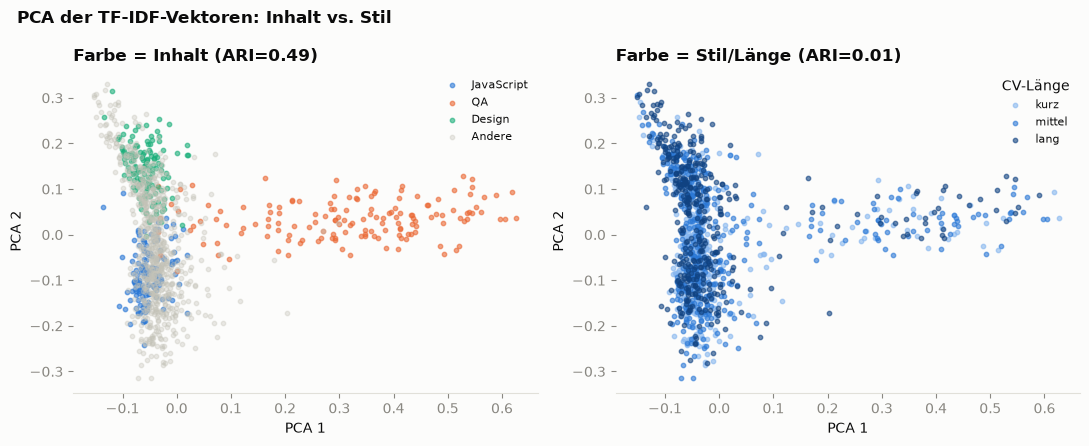

In [6]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X.toarray())

top3 = sample["Primary Keyword"].value_counts().head(3).index.tolist()
content_group = sample["Primary Keyword"].where(sample["Primary Keyword"].isin(top3), "Andere")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for cat, color in zip(top3, CAT3):
    mask = content_group == cat
    axes[0].scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.6, color=color, label=cat)
mask_other = content_group == "Andere"
axes[0].scatter(coords[mask_other, 0], coords[mask_other, 1], s=10, alpha=0.35, color=OTHER_GREY, label="Andere")
axes[0].set_title(f"Farbe = Inhalt (ARI={ari_content:.2f})", loc="left", color=INK, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8, loc="best")

for bucket, color in zip(["kurz", "mittel", "lang"], BLUE_ORDINAL[::2]):
    mask = length_bucket == bucket
    axes[1].scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.6, color=color, label=bucket)
axes[1].set_title(f"Farbe = Stil/Länge (ARI={ari_style:.2f})", loc="left", color=INK, fontweight="bold")
axes[1].legend(frameon=False, fontsize=8, loc="best", title="CV-Länge")

for ax in axes:
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.grid(visible=False)

fig.suptitle("PCA der TF-IDF-Vektoren: Inhalt vs. Stil", x=0.02, ha="left", color=INK, fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()


### Zwischenfazit Frage 1

Auf dieser Stichprobe clustert der Rohtext klar stärker nach **Inhalt** als nach **Stil**:
ARI(Cluster, Primary Keyword) = 0.49 vs. ARI(Cluster, CV-Länge) = 0.01. Visuell zeigt sich
das im PCA-Plot: QA-Profile bilden einen klar abgetrennten Arm (vermutlich durch
domänenspezifisches Testing-Vokabular), während die Terzile der CV-Länge keine erkennbare
Struktur im gleichen Raum erzeugen.

Das ist zunächst eine positive Nachricht für die Baseline: TF-IDF-Cluster bilden grob Rollen
ab, nicht Textlänge. Das heißt aber nicht, dass die Methode unempfindlich gegenüber Stil
ist – CV-Länge ist nur eines von mehreren möglichen Stilmerkmalen, und ARI misst nur harte
Cluster-Übereinstimmung, keine Verschiebung einzelner Similarity-Scores (siehe Abschnitt 4–5).


## 4. Tonalität als Proxy

Lexikon-basierte Tonalitäts-Merkmale: Häufigkeit von *hedging* ("maybe", "might", "try", …)
vs. *confidence*-Wörtern ("proven", "successfully", "led", …), Ich-Perspektive, Ausrufezeichen,
Satzlänge. Um zu prüfen, ob Tonalität den Baseline-Score verschiebt **obwohl die Domäne
gleich bleibt**, berechnen wir `same_kw_sim`: die Cosine Similarity jedes CVs zu einem
Text-Zentroid aus Job-Postings **des gleichen** `Primary Keyword` (Inhalt/Skills also
grob konstant gehalten) und korrelieren die Tonalitäts-Merkmale damit.


In [7]:
HEDGE_WORDS = {"maybe", "perhaps", "might", "could", "somewhat", "try", "trying",
               "hope", "hopefully", "possibly", "sort", "kind"}
CONFIDENCE_WORDS = {"expert", "proven", "successfully", "excellent", "outstanding",
                     "lead", "led", "achieved", "delivered", "strong", "advanced"}

def tone_features(text: str) -> dict:
    words = re.findall(r"[a-zA-Z']+", text.lower())
    n = max(len(words), 1)
    n_sent = max(len(re.split(r"[.!?]+", text)), 1)
    return {
        "avg_sent_len": n / n_sent,
        "exclam_rate": text.count("!") / n,
        "first_person_rate": sum(1 for w in words if w in {"i", "my", "me"}) / n,
        "hedge_rate": sum(1 for w in words if w in HEDGE_WORDS) / n,
        "confidence_rate": sum(1 for w in words if w in CONFIDENCE_WORDS) / n,
        "upper_word_rate": sum(1 for w in text.split() if w.isupper() and len(w) > 1) / max(len(text.split()), 1),
    }

tone_df = pd.DataFrame([tone_features(t) for t in sample["CV"]])

jobs = pd.read_parquet(JOB_PATH).dropna(subset=["Long Description", "Primary Keyword"])
job_centroids = {}
for kw in top_keywords:
    texts = jobs.loc[jobs["Primary Keyword"] == kw, "Long Description"]
    texts = texts.sample(min(30, len(texts)), random_state=SEED)
    job_centroids[kw] = " ".join(texts.tolist())

job_vec = vectorizer.transform([job_centroids[kw] for kw in top_keywords])
sim_matrix = cosine_similarity(X, job_vec)
kw_index = {kw: i for i, kw in enumerate(top_keywords)}
sample["same_kw_sim"] = [sim_matrix[i, kw_index[pk]] for i, pk in enumerate(sample["Primary Keyword"])]

print("same_kw_sim (Cosine Similarity zu Jobs der gleichen Primary Keyword-Klasse):")
print(sample["same_kw_sim"].describe())


same_kw_sim (Cosine Similarity zu Jobs der gleichen Primary Keyword-Klasse):
count    1200.000000
mean        0.237280
std         0.093932
min         0.024253
25%         0.170083
50%         0.228820
75%         0.293653
max         0.578942
Name: same_kw_sim, dtype: float64


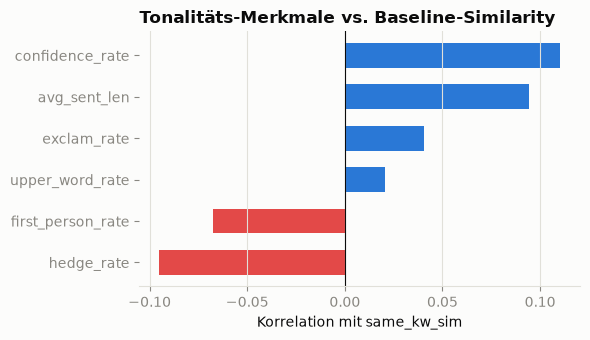

,corr_with_same_kw_sim
hedge_rate,-0.094928
first_person_rate,-0.067480
upper_word_rate,0.020348
exclam_rate,0.040595
avg_sent_len,0.094527
confidence_rate,0.110169


In [8]:
tone_corr = tone_df.apply(lambda col: np.corrcoef(col, sample["same_kw_sim"])[0, 1]).sort_values()

fig, ax = plt.subplots(figsize=(6, 3.5))
colors = [BLUE if v >= 0 else RED for v in tone_corr.values]
ax.barh(tone_corr.index, tone_corr.values, color=colors, height=0.6)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Korrelation mit same_kw_sim")
ax.set_title("Tonalitäts-Merkmale vs. Baseline-Similarity", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tone_corr.to_frame("corr_with_same_kw_sim")


### Beobachtung Tonalität

Confidence-Sprache ("proven", "successfully", "led", …) korreliert leicht positiv mit
`same_kw_sim` (r=0.11), Hedging ("maybe", "might", "try", …) und Ich-Perspektive leicht
negativ (r=-0.09 bzw. -0.07). Die Effekte sind auf dieser Stichprobe klein, aber konsistent
in der erwarteten Richtung: selbstbewusst formulierte CVs liegen textuell näher an
Jobtexten (die selbst meist in aktiver, confidence-lastiger Sprache geschrieben sind),
zurückhaltend formulierte CVs etwas weiter weg – bei vermutlich gleichen zugrunde liegenden
Skills.

→ Tonalität (insb. hedging vs. confidence, Ich- vs. neutrale Perspektive) ist ein
plausibler Proxy-Kandidat für die counterfactual Zwillinge.


## 5. Bildungsweg als Proxy

Der Datensatz hat **kein strukturiertes Bildungsfeld** – Bildungsweg-Signale stecken, wenn
überhaupt, im Freitext. Wir extrahieren drei grobe Regex-Marker (Nennung von
Universität/Abschluss, Selbstlern-/Bootcamp-Sprache, Zertifizierung) und vergleichen jeweils
den mittleren `same_kw_sim`-Score zwischen Profilen mit und ohne diese Nennung.

**Achtung:** Marker mit niedriger Prävalenz (wenige Treffer in der Stichprobe) liefern
instabile Mittelwerte – Prävalenz wird daher mit ausgegeben.


In [9]:
EDU_PATTERNS = {
    "university_degree": re.compile(r"\b(?:bachelor|master|ph\.?d|mba|university|college)\b", re.I),
    "self_taught": re.compile(r"\b(?:self[- ]taught|bootcamp|autodidact)\b", re.I),
    "certification": re.compile(r"\b(?:certified|certificate|certification)\b", re.I),
}

rows = []
for name, pattern in EDU_PATTERNS.items():
    has_marker = sample["CV"].str.contains(pattern, na=False)
    means = sample.groupby(has_marker)["same_kw_sim"].mean()
    rows.append({
        "marker": name,
        "prevalence": has_marker.mean(),
        "n_mentioned": int(has_marker.sum()),
        "mean_sim_ohne": means.get(False, np.nan),
        "mean_sim_mit": means.get(True, np.nan),
    })

edu_summary = pd.DataFrame(rows).set_index("marker")
edu_summary


,prevalence,n_mentioned,mean_sim_ohne,mean_sim_mit
marker,,,,
university_degree,0.105833,127,0.239354,0.219753
self_taught,0.003333,4,0.237416,0.196582
certification,0.061667,74,0.235809,0.259656


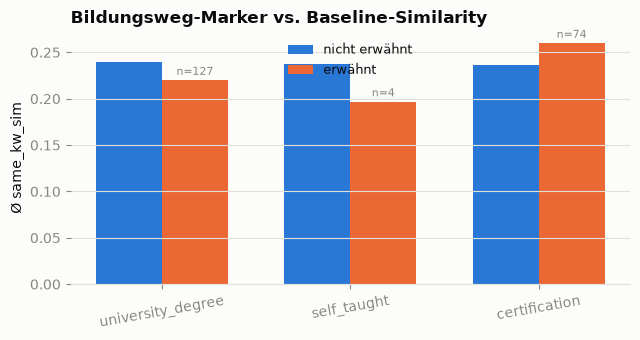

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
x = np.arange(len(edu_summary))
width = 0.35
ax.bar(x - width / 2, edu_summary["mean_sim_ohne"], width, color=BLUE, label="nicht erwähnt")
ax.bar(x + width / 2, edu_summary["mean_sim_mit"], width, color=ORANGE, label="erwähnt")
ax.set_xticks(x)
ax.set_xticklabels(edu_summary.index, rotation=10)
ax.set_ylabel("Ø same_kw_sim")
ax.set_title("Bildungsweg-Marker vs. Baseline-Similarity", loc="left", color=INK, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", visible=False)

for i, n in enumerate(edu_summary["n_mentioned"]):
    ax.annotate(f"n={n}", (i + width / 2, edu_summary['mean_sim_mit'].iloc[i]),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8, color=MUTED)

plt.tight_layout()
plt.show()


### Beobachtung Bildungsweg

Nennung von Universität/Abschluss korreliert mit einem **niedrigeren** `same_kw_sim`-Score
(0.220 vs. 0.239 ohne Nennung, n=127) – vermutlich weil akademische Formulierungen vom eher
technischen Jobtext-Vokabular wegführen. Zertifizierungs-Nennungen zeigen das umgekehrte
Bild: ein **höherer** Score (0.260 vs. 0.236, n=74), plausibel weil Zertifikatsnamen oft
exakte Tech-/Tool-Begriffe enthalten, die auch in Jobtexten auftauchen.

Der `self_taught`-Marker zeigt den größten Unterschied (0.197 vs. 0.237), ist aber mit n=4
Treffern in der Stichprobe statistisch nicht belastbar – Kandidat für eine gezieltere
Nacherhebung (größere Stichprobe, zusätzliche Marker) statt für eine Schlussfolgerung hier.

→ *Wie* der Bildungsweg formuliert wird (akademisch vs. zertifikatsbasiert vs.
autodidaktisch), scheint den Score zu verschieben, obwohl Inhalt/Rolle gleich bleiben – der
stärkste der hier gemessenen Effekte.


## 6. Englischkenntnisse als Demografie-Proxy

`English Level` ist ein selbstberichtetes, ordinales Feld – es kann indirekt mit Herkunft
(Non-Native-Speaker) korrelieren. Zwei Checks: (a) hängt die **Textlänge/Verbosität** (ein
reines Stilmerkmal) mit dem Level zusammen, über den gesamten Datensatz? (b) hängt der
**Baseline-Score** (`same_kw_sim`, auf unserer Stichprobe) mit dem Level zusammen?


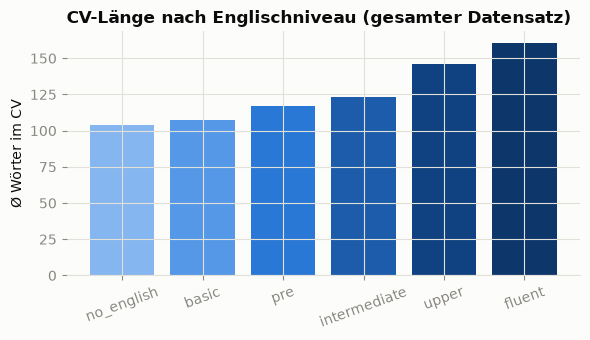

English Level
no_english      103.845588
basic           107.426646
pre             117.275980
intermediate    123.239775
upper           145.743096
fluent          160.562294
Name: CV, dtype: float64

In [11]:
level_order = ["no_english", "basic", "pre", "intermediate", "upper", "fluent"]

cv_all = pd.read_parquet(CV_PATH).dropna(subset=["English Level", "CV"])
mean_words_by_level = (
    cv_all.groupby("English Level")["CV"]
    .apply(lambda s: s.str.split().str.len().mean())
    .reindex(level_order)
)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(level_order, mean_words_by_level.values, color=BLUE_ORDINAL[:len(level_order)])
ax.set_ylabel("Ø Wörter im CV")
ax.set_title("CV-Länge nach Englischniveau (gesamter Datensatz)", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

mean_words_by_level


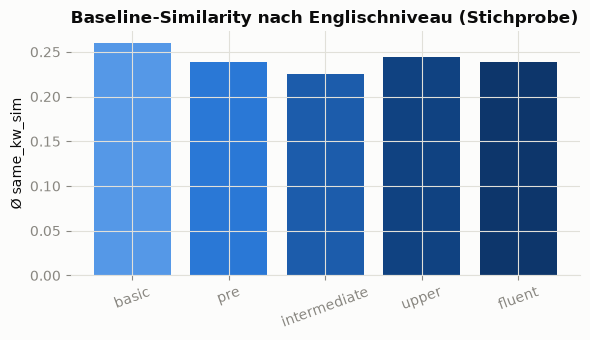

,mean,count
English Level,,
no_english,NaN,NaN
basic,0.259950,25.0
pre,0.239059,113.0
intermediate,0.225676,363.0
upper,0.244290,458.0
fluent,0.238275,237.0


In [12]:
sim_by_level = sample.groupby("English Level")["same_kw_sim"].agg(["mean", "count"]).reindex(level_order)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(level_order, sim_by_level["mean"].values, color=BLUE_ORDINAL[:len(level_order)])
ax.set_ylabel("Ø same_kw_sim")
ax.set_title("Baseline-Similarity nach Englischniveau (Stichprobe)", loc="left", color=INK, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

sim_by_level


### Beobachtung Englischkenntnisse

Die CV-Länge steigt über den gesamten Datensatz klar monoton mit dem selbstberichteten
Englischniveau (Ø 104 Wörter bei `no_english` bis Ø 161 Wörter bei `fluent`) – ein
deutliches Stilsignal, das mit dem Englischniveau zusammenhängt und damit indirekt mit
Herkunft/Native-Speaker-Status korrelieren kann.

Der direkte Effekt auf den Baseline-Score (`same_kw_sim`) ist auf unserer Stichprobe
dagegen schwächer und nicht monoton (0.226–0.260 über die Level; `no_english` kommt in der
Stichprobe gar nicht vor, `basic` nur mit n=25) – hier bräuchte es eine größere, gezielt
nach Englischniveau gezogene Stichprobe, um einen Effekt von Stichproben-Rauschen zu
unterscheiden.

→ Textlänge/Verbosität ist der robustere der beiden Englisch-bezogenen Proxy-Kandidaten.


## 7. Welche Terms treiben die Similarity? (Sensitivitätsanalyse)

Die Terme mit dem höchsten mittleren TF-IDF-Gewicht sind die, die den Cosine-Similarity-Score
am stärksten beeinflussen. Wir markieren grob, welche davon in der ESCO-Vokabular-Liste
(`data/raw/esco/skills_en.csv`, `preferredLabel` + `altLabels`, als Unigramme) auftauchen.

**Caveat:** Das ist ein **grober Unigramm-Abgleich**, keine echte Skill-Extraktion – ESCO hat
~14.000 Labels, viele davon mehrwortig mit generischen Bestandteilen ("manage *staff*",
"*apply* practices"), wodurch auch generische Wörter als "ESCO-Token" durchgehen. Für die
echte Extraktion siehe `scripts/esco_extractor.py` (ESCOX-Wrapper).


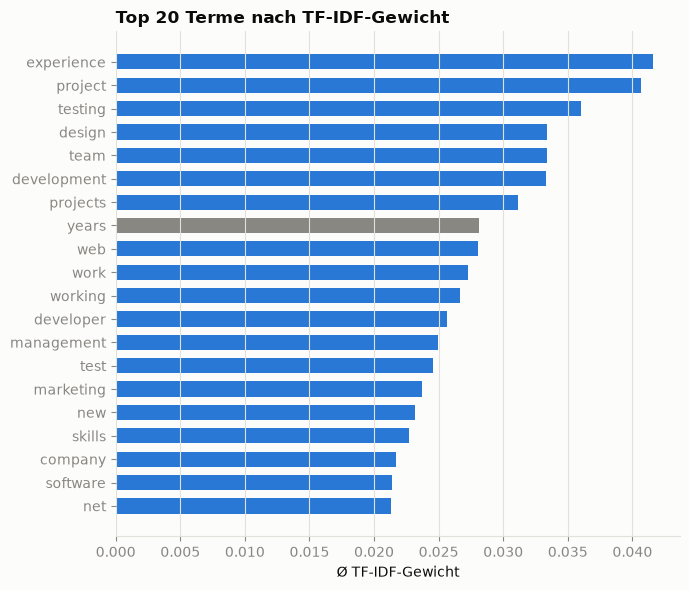

,term,mean_tfidf,esco_token_match
0,experience,0.041604,True
1,project,0.040660,True
2,testing,0.036015,True
3,design,0.033415,True
4,team,0.033372,True
5,development,0.033274,True
6,projects,0.031148,True
7,years,0.028107,False
8,web,0.028027,True
9,work,0.027255,True


In [13]:
esco = pd.read_csv(ESCO_PATH)
esco_tokens = set()
for col in ["preferredLabel", "altLabels"]:
    for value in esco[col].dropna():
        for phrase in str(value).split("\n"):
            esco_tokens.update(re.findall(r"[a-zA-Z]+", phrase.lower()))

mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
terms = np.array(vectorizer.get_feature_names_out())
top_idx = np.argsort(mean_tfidf)[::-1][:20]

top_terms = pd.DataFrame({
    "term": terms[top_idx],
    "mean_tfidf": mean_tfidf[top_idx],
    "esco_token_match": [t in esco_tokens for t in terms[top_idx]],
})

fig, ax = plt.subplots(figsize=(7, 6))
colors = [BLUE if m else MUTED for m in top_terms["esco_token_match"]]
ax.barh(top_terms["term"][::-1], top_terms["mean_tfidf"][::-1], color=colors[::-1], height=0.65)
ax.set_xlabel("Ø TF-IDF-Gewicht")
ax.set_title("Top 20 Terme nach TF-IDF-Gewicht", loc="left", color=INK, fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

top_terms


### Beobachtung Sensitivitätsanalyse

Fast alle Top-20-Terme nach TF-IDF-Gewicht ("experience", "project", "team", "development",
"work", …) matchen unseren groben ESCO-Unigramm-Check – aber nicht, weil sie konkrete
Skills sind, sondern weil ESCO mit ~14.000 Labels fast jedes generische Arbeits-/
Lebenslaufwort irgendwo als Teil eines Labels enthält. Inhaltlich sind das überwiegend
**CV-Boilerplate-Wörter**, keine spezifischen Skills (echte Tech-Skills wie "java",
"python", "react" tauchen erst weiter unten in der Rangliste auf).

Das ist selbst ein relevanter Befund: Die rohe TF-IDF+Cosine-Baseline wird stark von
generischem Lebenslauf-Vokabular getrieben, nicht primär von Skills – ein zusätzlicher
Grund, warum die ESCOX-basierte Skill-Extraktion (statt Roh-TF-IDF-Vokabular) der richtige
Weg für robustes Matching ist, und zugleich eine Erklärung dafür, warum die Baseline
überhaupt anfällig für Stil-/Tonalitäts-Proxies ist: generische Formulierungen dominieren
das Gewicht.


## 8. Zusammenfassung – Proxy-Kandidaten für counterfactual Zwillinge

**Zu den Leitfragen:**

- *Clustert der Rohtext nach Stil oder nach Inhalt?* Primär nach Inhalt (ARI=0.49 vs.
  Primary Keyword, ARI=0.01 vs. CV-Länge). Die Baseline ist auf grober Ebene also nicht
  stilblind, bricht aber bei feineren Stilmerkmalen (Tonalität, Bildungsweg-Framing)
  durchaus ein, wie Abschnitt 4–5 zeigen.
- *Gibt es Hinweise auf Demografie-Proxys wie Englischkenntnisse?* Ja, indirekt:
  Englischniveau korreliert klar mit CV-Länge/Verbosität (Abschnitt 6) – ein Stilmerkmal,
  das potenziell mit Herkunft/Native-Speaker-Status zusammenhängt. Der direkte Effekt auf
  den `same_kw_sim`-Score ist in dieser Stichprobe schwächer und bräuchte eine gezieltere
  Stichprobe zur Bestätigung.

**Proxy-Kandidaten, die wir bei den counterfactual Zwillingen gezielt variieren sollten
(Skills/Inhalt dabei konstant halten):**

1. **Tonalität:** Confidence- vs. Hedging-Sprache, Ich-Perspektive vs. neutrale
   Formulierung, Satzlänge – konsistente, wenn auch kleine Korrelationen mit dem
   Baseline-Score (Abschnitt 4).
2. **Bildungsweg-Framing:** Akademisch (Universität/Abschluss) vs. zertifikatsbasiert vs.
   autodidaktisch formuliert – der größte gemessene Effekt (Abschnitt 5); der
   self-taught-Befund braucht wegen kleiner Fallzahl noch Absicherung.
3. **Textlänge/Verbosität:** als Begleitsignal zum Englischniveau – bei der
   Zwillingsgenerierung sollte Länge kontrolliert/konstant gehalten werden, damit sie nicht
   als Störvariable mit Tonalität/Bildungsweg konfundiert.

**Nächste Schritte:** LLM-generierte counterfactual Zwillinge, die genau diese drei
Dimensionen variieren, während ESCO-Skill-Labels (via ESCOX) invariant bleiben;
anschließend Jaccard-Invarianz der Skill-Labels **und** Delta im TF-IDF-Cosine-Score
messen, um die Proxy-Sensitivität der Baseline direkt zu quantifizieren – statt nur
indirekt wie hier.
